# Phase II : Reddit Activity and Trading Volume

## Project objective

Our project examines whether Reddit ticker mentions and sentiment can help
predict unusually high trading volume on the next trading day. We plan to
compare a model using historical trading volume alone with a model that
also includes Reddit activity and sentiment features.

## Data source and scope

Source: https://huggingface.co/datasets/SocialGrep/reddit-wallstreetbets-aug-2021

This notebook explores 1,001,160 comments from r/wallstreetbets collected
during August 2021. The dataset comes from SocialGrep and is accessed
through an archived version of its Hugging Face repository.

Available fields include comment IDs, UTC timestamps, comment text,
Reddit scores, and supplied sentiment scores. Author information is
not included.

This historical dataset differs from our original plan to collect
approximately 90 trading days from r/wallstreetbets and r/stocks.
We will use it to develop and evaluate our preprocessing and feature
construction approach. Its short date range limits the strength of
any later predictive conclusions.

## Notebook organization

1. Data loading and quality checks
2. Comment cleaning and text exploration
3. Ticker extraction and mention analysis
4. Keyword and sentiment analysis
5. Phase III modeling plan and limitations

# 1. Data Exploration (about 25% of notebook)

In [1]:
import pandas as pd
import re

pd.set_option("display.max_colwidth", 200)

DATA_URL = (
    "https://huggingface.co/datasets/"
    "SocialGrep/reddit-wallstreetbets-aug-2021/"
    "resolve/14cd0137fe78c47ba3afb0762e8081d925adf246/"
    "wsb-aug-2021-comments.csv"
)

def load_comments(url):
    """Load comments and convert Unix timestamps to UTC."""
    df = pd.read_csv(
        url,
        dtype={"id": "string"},
        low_memory=False
    )

    df["created_datetime"] = pd.to_datetime(
        df["created_utc"],
        unit="s",
        utc=True,
        errors="coerce"
    )

    return df

comments = load_comments(DATA_URL)

print(f"Total comments: {len(comments):,}")
print(f"Columns: {comments.shape[1]}")
print("Earliest timestamp:", comments["created_datetime"].min())
print("Latest timestamp:", comments["created_datetime"].max())
print("Duplicate comment IDs:", comments["id"].duplicated().sum())

display(comments.head(3))

Total comments: 1,001,160
Columns: 11
Earliest timestamp: 2021-08-01 00:00:03+00:00
Latest timestamp: 2021-08-31 23:59:54+00:00
Duplicate comment IDs: 0


,type,id,subreddit.id,subreddit.name,subreddit.nsfw,created_utc,permalink,body,sentiment,score,created_datetime
0,comment,hb4hdm3,2th52,wallstreetbets,False,1630454394,https://old.reddit.com/r/wallstreetbets/comments/pfdkjw/what_are_your_moves_tomorrow_september_01_2021/hb4hdm3/,What's updog,NaN,3,2021-08-31 23:59:54+00:00
1,comment,hb4hdm8,2th52,wallstreetbets,False,1630454394,https://old.reddit.com/r/wallstreetbets/comments/pfdkjw/what_are_your_moves_tomorrow_september_01_2021/hb4hdm8/,Don’t tell em,NaN,1,2021-08-31 23:59:54+00:00
2,comment,hb4hdjc,2th52,wallstreetbets,False,1630454393,https://old.reddit.com/r/wallstreetbets/comments/pfdkjw/what_are_your_moves_tomorrow_september_01_2021/hb4hdjc/,"I realize this, ive been losing thousands shooting for stars, I just buy in the money every time, small profits better than none. I just buy at dips to guarantee some income added",0.6369,2,2021-08-31 23:59:53+00:00


### Dataset size and missing values

We first examine the dataset's size, date coverage, and missing values.
We also check for duplicate comment IDs and unavailable comment text,
including comments marked as deleted or removed.

In [2]:
# Basic dataset statistics
summary = pd.Series({
    "Total comments": len(comments),
    "Unique comment IDs": comments["id"].nunique(),
    "Duplicate comment IDs": comments["id"].duplicated().sum(),
    "Earliest timestamp (UTC)": comments["created_datetime"].min(),
    "Latest timestamp (UTC)": comments["created_datetime"].max(),
    "Invalid timestamps": comments["created_datetime"].isna().sum()
}, name="Value")

display(summary.to_frame())

# Missing values by column
missing_summary = pd.DataFrame({
    "Missing count": comments.isna().sum(),
    "Missing percent": comments.isna().mean().mul(100).round(2)
})

display(missing_summary)

# Check unavailable text without changing the original comments
text_check = comments["body"].astype("string").str.strip()

text_quality = pd.Series({
    "Missing text": text_check.isna().sum(),
    "Blank text": text_check.eq("").sum(),
    "Deleted comments": text_check.str.lower().eq("[deleted]").sum(),
    "Removed comments": text_check.str.lower().eq("[removed]").sum()
}, name="Comment count")

display(text_quality.to_frame())

,Value
Total comments,1001160
Unique comment IDs,1001160
Duplicate comment IDs,0
Earliest timestamp (UTC),2021-08-01 00:00:03+00:00
Latest timestamp (UTC),2021-08-31 23:59:54+00:00
Invalid timestamps,0


,Missing count,Missing percent
type,0,0.00
id,0,0.00
subreddit.id,0,0.00
subreddit.name,0,0.00
subreddit.nsfw,0,0.00
created_utc,0,0.00
permalink,0,0.00
body,14,0.00
sentiment,295438,29.51
score,0,0.00


,Comment count
Missing text,14
Blank text,0
Deleted comments,43471
Removed comments,143740


### Data quality findings

The dataset contains 1,001,160 comments spanning August 2021 in UTC.
All comment IDs are unique, and all timestamps parsed successfully.

There are 14 comments with missing text, 43,471 marked as deleted,
and 143,740 marked as removed. These records cannot support text
analysis and will be excluded, leaving 813,935 usable comments.

The supplied sentiment score is missing for 29.51% of the original
records. We will retain usable comments even when sentiment is missing,
since their text can still support ticker extraction and our own
sentiment analysis. Missing sentiment will not be treated as neutral.

In [3]:
def clean_comments(df):
    """Exclude unavailable text while preserving the original wording."""
    text = df["body"].astype("string").str.strip()

    usable = (
        text.notna()
        & text.ne("")
        & ~text.str.lower().isin(["[deleted]", "[removed]"])
    )

    cleaned = df.loc[usable].copy()
    cleaned["body"] = text.loc[usable]

    return cleaned

comments_clean = clean_comments(comments)

print(f"Original comments: {len(comments):,}")
print(f"Usable comments: {len(comments_clean):,}")
print(f"Excluded comments: {len(comments) - len(comments_clean):,}")

# Recheck sentiment coverage after excluding unavailable text
print(
    "Missing sentiment among usable comments:",
    f"{comments_clean['sentiment'].isna().mean():.2%}"
)

Original comments: 1,001,160
Usable comments: 813,935
Excluded comments: 187,225
Missing sentiment among usable comments: 13.30%


### Text length distribution and sample comments

We examine comment lengths to understand how much text is available
for keyword and sentiment analysis. Length is measured in characters
and whitespace-separated words. We also inspect a random sample
to understand the language and context of the comments.

,char_count,word_count
count,813935.0,813935.00
mean,92.63,15.80
std,149.18,21.73
min,1.0,1.00
25%,26.0,5.00
50%,52.0,10.00
75%,101.0,19.00
90%,192.0,33.00
99%,749.0,99.00
max,9820.0,1648.00


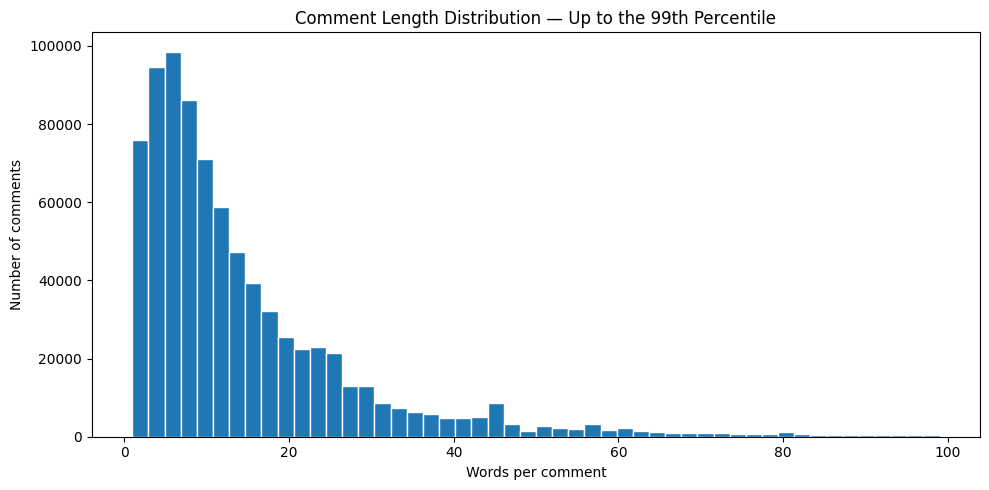

,body,word_count,sentiment
1001144,It went from 90 degrees and Sunny yesterday to 60 degrees and Rainy today here in Denver. Kinda resembles my portfolio this week,23,0.3612
40438,Oof,1,NaN
508300,Nobody gives af \n\nTake that shit to r/politics,8,-0.5574
431125,"I have purchased dips (Brexit, elections where the winner wasn't favored by the market, etc.), **but I don't trust China.**",20,-0.4251
219568,Smells like 🦍s in here,5,0.3612


In [4]:
import matplotlib.pyplot as plt

comments_clean["char_count"] = comments_clean["body"].str.len()
comments_clean["word_count"] = (
    comments_clean["body"].str.split().str.len()
)

# Summary includes the full range of comment lengths
display(
    comments_clean[["char_count", "word_count"]]
    .describe(percentiles=[0.25, 0.50, 0.75, 0.90, 0.99])
    .round(2)
)

# Limit the chart to the 99th percentile for readability
upper_limit = comments_clean["word_count"].quantile(0.99)

plt.figure(figsize=(10, 5))
plt.hist(
    comments_clean.loc[
        comments_clean["word_count"] <= upper_limit,
        "word_count"
    ],
    bins=50,
    edgecolor="white"
)
plt.title("Comment Length Distribution — Up to the 99th Percentile")
plt.xlabel("Words per comment")
plt.ylabel("Number of comments")
plt.tight_layout()
plt.show()

# Display complete sample comments without changing global settings
with pd.option_context("display.max_colwidth", None):
    display(
        comments_clean[["body", "word_count", "sentiment"]]
        .sample(5, random_state=42)
    )

### Interpretation of comment lengths

The median comment contains 10 words, while the mean is 15.80 words.
The higher mean reflects a small number of long comments. The 90th
percentile is 33 words, and the longest comment contains 1,648 words.
The histogram displays comments up to the 99th percentile of 99 words
for readability. Longer comments remain in the dataset.

The sample comments include brief reactions, informal language,
and discussions unrelated to specific stocks. This supports filtering
for ticker mentions before constructing stock-specific features.
Short comments may also require surrounding context to interpret
sentiment accurately.

One sample compares rainy weather with the author's portfolio and
receives a positive supplied sentiment score of 0.3612. This illustrates
why the supplied scores need review before being interpreted as
bullish or bearish trading sentiment.

### Ticker Extraction

In [5]:
# Keep the current list for exploration
tickers = [
    "GME", "AMC", "TSLA", "SPY", "QQQ", "AAPL", "AMD",
    "NVDA", "BABA", "CRWD", "PLTR", "BB", "NOK",
    "CLOV", "WISH", "SOFI", "SPCE", "HOOD"
]

ticker_options = "|".join(map(re.escape, tickers))

# Bare symbols must be uppercase: GME, WISH
# Dollar-prefixed symbols may use any case: $gme, $wish
ticker_pattern = re.compile(
    rf"(?<!\w)(?:"
    rf"\$(?P<cashtag>(?i:{ticker_options}))"
    rf"|(?P<uppercase>{ticker_options})"
    rf")(?!\w)"
)

def find_tickers(text):
    """Return unique recognized tickers mentioned in a comment."""
    found = {
        (match.group("cashtag") or match.group("uppercase")).upper()
        for match in ticker_pattern.finditer(str(text))
    }
    return sorted(found)

comments_clean["tickers"] = comments_clean["body"].apply(find_tickers)

ticker_comments = comments_clean.loc[
    comments_clean["tickers"].str.len() > 0
].copy()

ticker_counts = (
    ticker_comments["tickers"]
    .explode()
    .value_counts()
    .reindex(tickers, fill_value=0)
    .sort_values(ascending=False)
    .rename_axis("ticker")
    .reset_index(name="comment_count")
)

print(f"Comments mentioning a tracked ticker: {len(ticker_comments):,}")

display(ticker_counts)
display(ticker_comments[["body", "tickers"]].head(15))

Comments mentioning a tracked ticker: 64,905


,ticker,comment_count
0,SPY,17069
1,GME,8464
2,HOOD,6605
3,AMC,5515
4,CLOV,4951
5,WISH,3758
6,BABA,3624
7,PLTR,3608
8,AMD,3321
9,TSLA,3113


,body,tickers
4,Are you saying I should or shouldn’t yolo my life savings into BABA $200 call options expiring next week?,[BABA]
17,Buy more AMC or buy GME?,"[AMC, GME]"
65,If BB can get to 400 I will finally have recovered,[BB]
85,AMC,[AMC]
119,I’ve held GME before and sold,[GME]
125,"That's what I was thinking too, going to open a few spreads capping out in that range. GME has made me tens of thousands of dollars already this year, no sense getting greedy",[GME]
196,Too late to FOMO into GME? (Again),[GME]
211,"WISH, ASTR, PTON Calls",[WISH]
260,Who exactly is dumb enough to be caught with a short position large enough to get squeezed in this day and age.\n\nGME squeezed because nobody could get their heads around it going higher. But now...,[GME]
266,"I pledge allegiance to the bags of the United States of America, and for which stands, one market, under all, invincible, with prosperity and otm call options for all. SPY to 500 eom.",[SPY]


### Ticker extraction findings

Our extraction rules identified 64,905 comments containing at least
one of the 18 tracked symbols. SPY had the most matching comments
(17,069), followed by GME (8,464) and HOOD (6,605). These counts
describe attention within our selected list, not all tickers on WSB.

Each ticker is counted once per comment. Comments mentioning multiple
tracked tickers contribute to each ticker's count, so the counts can
sum to more than the number of unique matching comments.

Requiring uppercase symbols or dollar-prefixed mentions reduces
false matches from ordinary lowercase words. However, it misses
lowercase symbols without a dollar sign, company names, and nicknames.
Uppercase ordinary words can still produce false matches.

SPY and QQQ are ETFs. We will distinguish these from individual stocks
and align the final symbol list with the trading-volume dataset.

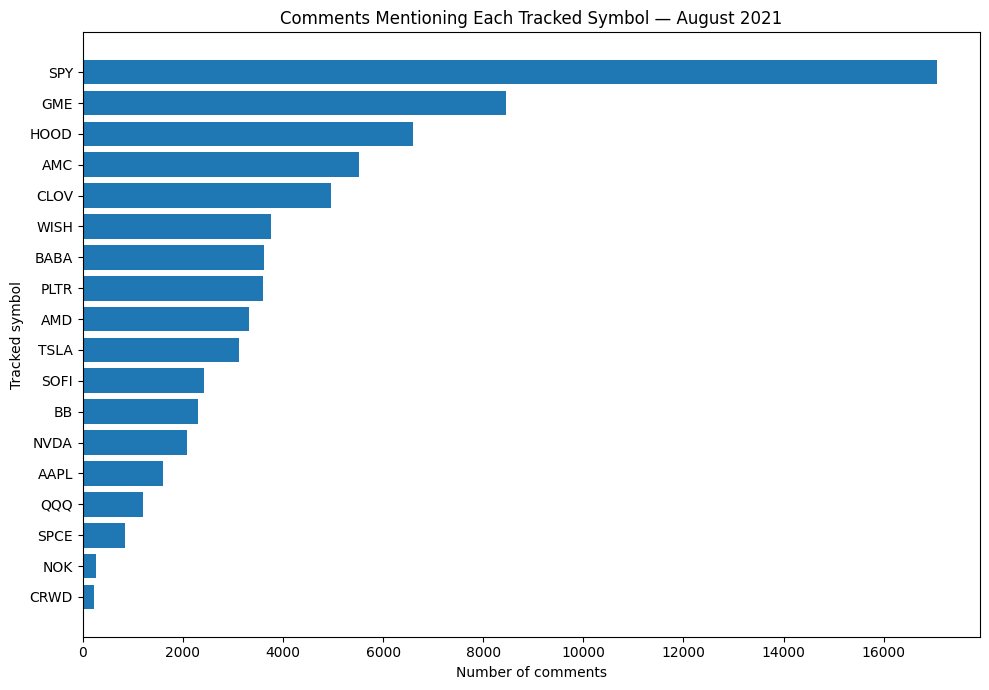

In [6]:
plot_counts = ticker_counts.sort_values("comment_count")

plt.figure(figsize=(10, 7))
plt.barh(plot_counts["ticker"], plot_counts["comment_count"])
plt.title("Comments Mentioning Each Tracked Symbol — August 2021")
plt.xlabel("Number of comments")
plt.ylabel("Tracked symbol")
plt.tight_layout()
plt.show()

### Before keyword analysis: need to review some tickers to check if ordinary words are getting through.

In [7]:
for ticker in ["WISH", "HOOD"]:
    matches = ticker_comments[
        ticker_comments["tickers"].apply(lambda values: ticker in values)
    ]

    print(f"\nSample matches for {ticker}:")
    with pd.option_context("display.max_colwidth", None):
        display(matches[["body", "tickers"]].sample(10, random_state=42))


Sample matches for WISH:


,body,tickers
508326,Things are not lookin too good for WISH bagholders....,[WISH]
601581,WISH's shareholder letter is probably the worst I've ever read. They may honestly go bankrupt within 2 years.,[WISH]
127290,WISH is loading. May be the next moon shot!!!,[WISH]
601313,"Wish is a scam pushed by this sub. I bought in and regret it. Every time I say that I do, get downvoted into oblivion. Someone made a thread how bad their earnings report from today was and it got deleted. \n\nWISH IS GARBAGE",[WISH]
571121,Nothing less than $9 for WISH.,[WISH]
812991,"Similar thing happened to my brother.\n\nSomeone in Florida stole his identity and bought a house in his name. He called the sheriff in the area said they wouldn't have any part of it and advised him to talk to a lawyer instead. He went down to the property to confront the guy but he wasn't there and instead talked to his wife. He claimed to be a bounty hunter on the trail of himself, ""the stolen identity,"" due to skipped bail. The lady offered sex in exchange for him to abandon the, ""search,"" and he took her offer. He made sure to get the hell out of there before the identity thief came back and if you believed any of this, I got WISH calls to sell you.",[WISH]
570215,"The irony is the stock is called WISH, if anything anyone should always think twice before buying stock just based off that name alone.",[WISH]
168564,Fuck WISH man wtf,[WISH]
661584,I got a cheap ass hoodie off WISH,[WISH]
582882,what do you think about discount on WISH?,[WISH]



Sample matches for HOOD:


,body,tickers
783655,Bought 30c of HOOD expiring in 2023..😀.,[HOOD]
897542,HOOD wrong way,[HOOD]
192775,Literally no one expected anything of HOOD.,[HOOD]
910990,"Imagine buying HOOD at $48 today and then dropping at $45 cause u fear it tanking. Imagine, just imagine. Couldn't be me",[HOOD]
865931,"With the way this market moves, I wouldn’t be surprised by a massive pump in HOOD before an epic crash in the coming days",[HOOD]
622037,My short $70c HOOD lookin' GOOD this friday!\n\nAlso GO 🍀! Crossing fingers for big green day.,[HOOD]
884715,"Damn I missed HOOD and MRNA runups this morning, sleeping in has its perks but that ain't one of em.",[HOOD]
898984,Way more profitable than HOOD. At least they rob ppl of money the proper way!,[HOOD]
910533,WSB finna get robbed in the $HOOD,[HOOD]
899136,HOOD,[HOOD]


### Manual review of ticker matches

We reviewed 10 randomly selected matches each for WISH and HOOD.
Most examples appeared relevant to the named company or stock.
However, the WISH sample included an unrelated story using
“WISH calls” as a joke and a comment about buying clothing from
the shopping platform.

Ticker matching therefore identifies candidate mentions rather
than verified stock discussions. Uppercase matching reduces
ordinary-word errors but does not resolve context. These small
samples do not establish accuracy across the full dataset.

For Phase III, we will review a larger sample and test whether
Claude can distinguish relevant stock discussion from unrelated
or ambiguous mentions before assigning trading sentiment.

### Daily comment activity and data coverage

We examine daily comment counts to check date coverage and variation
in discussion activity. We compare the original records with usable
comments to see how deleted, removed, and missing text affect coverage.

Dates are grouped in UTC for this descriptive check. Trading-day
features will require a separate market-time cutoff.

,original_comments,usable_comments,excluded_comments,excluded_percent
date_utc,,,,
2021-08-01 00:00:00+00:00,21563,18246,3317,15.38
2021-08-02 00:00:00+00:00,33357,27658,5699,17.08
2021-08-03 00:00:00+00:00,38443,31580,6863,17.85
2021-08-04 00:00:00+00:00,44860,36244,8616,19.21
2021-08-05 00:00:00+00:00,43376,33949,9427,21.73
2021-08-06 00:00:00+00:00,37271,29759,7512,20.16
2021-08-07 00:00:00+00:00,17691,14293,3398,19.21
2021-08-08 00:00:00+00:00,19049,15390,3659,19.21
2021-08-09 00:00:00+00:00,33312,25882,7430,22.30


Dates with no original records: 0


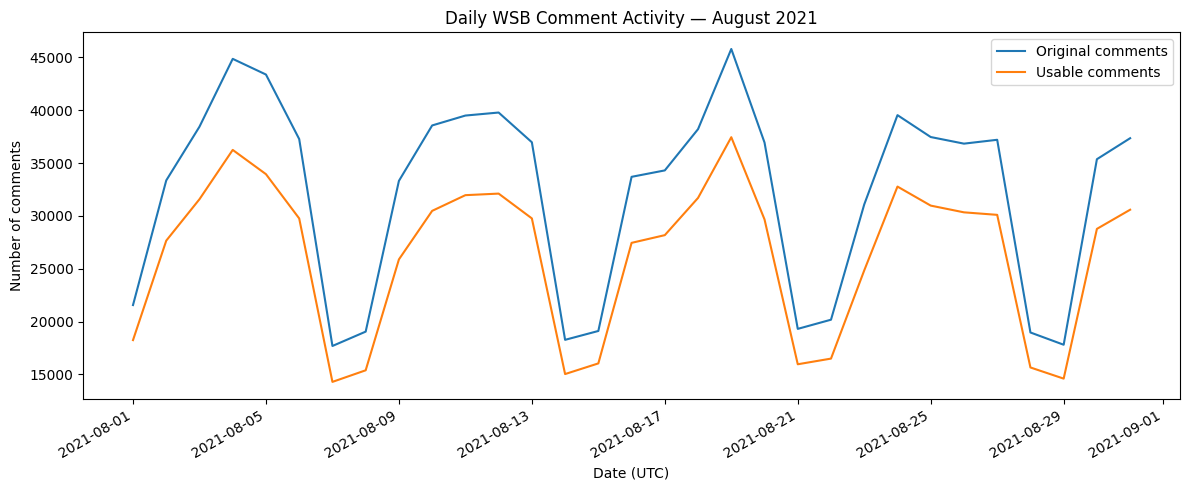

In [8]:
# Count original and usable comments by UTC calendar date
august_dates = pd.date_range(
    "2021-08-01", "2021-08-31", freq="D", tz="UTC"
)

daily_counts = pd.DataFrame({
    "original_comments": comments.groupby(
        comments["created_datetime"].dt.floor("D")
    ).size(),
    "usable_comments": comments_clean.groupby(
        comments_clean["created_datetime"].dt.floor("D")
    ).size()
}).reindex(august_dates, fill_value=0)

daily_counts.index.name = "date_utc"

daily_counts["excluded_comments"] = (
    daily_counts["original_comments"]
    - daily_counts["usable_comments"]
)

daily_counts["excluded_percent"] = (
    daily_counts["excluded_comments"]
    .div(daily_counts["original_comments"].replace(0, float("nan")))
    .mul(100)
    .round(2)
)

display(daily_counts)

print(
    "Dates with no original records:",
    (daily_counts["original_comments"] == 0).sum()
)

# Plot daily activity
fig, ax = plt.subplots(figsize=(12, 5))

ax.plot(
    daily_counts.index,
    daily_counts["original_comments"],
    label="Original comments"
)
ax.plot(
    daily_counts.index,
    daily_counts["usable_comments"],
    label="Usable comments"
)

ax.set_title("Daily WSB Comment Activity — August 2021")
ax.set_xlabel("Date (UTC)")
ax.set_ylabel("Number of comments")
ax.legend()
fig.autofmt_xdate()
plt.tight_layout()
plt.show()

### Daily activity findings

All 31 UTC dates in August contain comments. Daily activity shows
a recurring weekly pattern, with lower counts on weekends.
August 19 had the highest activity, with 45,795 original comments
and 37,447 usable comments.

The original and cleaned series follow similar patterns, suggesting
that excluding unavailable text preserves the broad activity trend.
However, the percentage excluded varies from 15.38% to 22.30%
across dates. This variation could affect comparisons of mention
counts and sentiment between days.

No dates are entirely missing, but this does not establish that
every comment was collected. Weekend activity also shows why we
need explicit rules for assigning comments to trading-day windows.
These UTC daily totals are descriptive and are not yet the
features used to predict next-day volume.

### Which types of threads these comments come from

In [9]:
# Extract parent thread IDs and URL title slugs
thread_parts = comments_clean["permalink"].str.extract(
    r"/comments/(?P<thread_id>[^/]+)/(?P<thread_slug>[^/]+)"
)

comments_clean["thread_id"] = thread_parts["thread_id"]
comments_clean["thread_slug"] = thread_parts["thread_slug"]

# Classify threads using their URL title slugs
def classify_thread(slug):
    if pd.isna(slug):
        return "Unknown"
    if "daily_discussion" in slug:
        return "Daily discussion"
    if "what_are_your_moves" in slug:
        return "What are your moves"
    if "weekend_discussion" in slug:
        return "Weekend discussion"
    return "Other threads"

comments_clean["thread_type"] = (
    comments_clean["thread_slug"].apply(classify_thread)
)

thread_summary = (
    comments_clean["thread_type"]
    .value_counts()
    .rename_axis("thread_type")
    .reset_index(name="comment_count")
)

thread_summary["percent"] = (
    thread_summary["comment_count"]
    .div(len(comments_clean))
    .mul(100)
    .round(2)
)

display(thread_summary)

print(
    "Unique identified threads:",
    comments_clean["thread_id"].nunique()
)

,thread_type,comment_count,percent
0,Other threads,305679,37.56
1,Daily discussion,229312,28.17
2,What are your moves,198844,24.43
3,Weekend discussion,80100,9.84


Unique identified threads: 24467


### Thread coverage findings

The usable comments span 24,467 identified threads. Daily Discussion
threads account for 28.17% of comments, “What are your moves” threads
account for 24.43%, and Weekend Discussion threads account for 9.84%.
The remaining 37.56% appear in other threads.

This dataset has a broader scope than our original Daily Discussion
collection plan. For exploration, we retain all thread types and
identify candidate ticker mentions within them. Before modeling,
we will decide whether to retain this broader scope or restrict
the analysis to recurring discussion threads.

These categories are inferred from URL title slugs and may not
classify every thread correctly. Different thread types may also
contain different kinds of discussion, which could affect ticker
counts and sentiment.

## Daily Ticker Coverage

In [10]:
# One row per comment–ticker pair
ticker_daily_rows = (
    ticker_comments[["id", "created_datetime", "tickers"]]
    .explode("tickers")
    .rename(columns={"tickers": "ticker"})
)

ticker_daily_rows["date_utc"] = (
    ticker_daily_rows["created_datetime"].dt.floor("D")
)

# Include every tracked ticker and all 31 UTC dates
daily_ticker_counts = (
    ticker_daily_rows
    .groupby(["date_utc", "ticker"])
    .size()
    .unstack(fill_value=0)
    .reindex(index=august_dates, columns=tickers, fill_value=0)
)

coverage_summary = pd.DataFrame({
    "total_candidate_comments": daily_ticker_counts.sum(),
    "days_with_mentions": daily_ticker_counts.gt(0).sum(),
    "zero_mention_days": daily_ticker_counts.eq(0).sum(),
    "median_daily_comments": daily_ticker_counts.median(),
    "max_daily_comments": daily_ticker_counts.max()
}).sort_values("total_candidate_comments", ascending=False)

display(coverage_summary)

,total_candidate_comments,days_with_mentions,zero_mention_days,median_daily_comments,max_daily_comments
ticker,,,,,
SPY,17069,31,0,593.0,1217
GME,8464,31,0,150.0,1877
HOOD,6605,31,0,65.0,2300
AMC,5515,31,0,154.0,608
CLOV,4951,31,0,86.0,860
WISH,3758,31,0,64.0,884
BABA,3624,31,0,90.0,504
PLTR,3608,31,0,80.0,542
AMD,3321,31,0,76.0,562


### Daily ticker coverage findings

Seventeen of the 18 tracked symbols have candidate mentions on every
UTC date in August. CRWD has mentions on 26 dates and no matches
on five dates.

Discussion volume differs substantially across symbols. SPY has a
median of 593 matching comments per day, compared with five for
NOK and three for CRWD. Sentiment averages based on only a few
comments may be less stable and should be accompanied by comment
counts.

Some symbols also show concentrated bursts of attention. HOOD
has a median of 65 matching comments per day but a maximum of
2,300. This supports examining changes in attention rather than
relying only on monthly totals. It does not establish that Reddit
activity predicts trading volume.

Zero-mention dates are retained. These represent no matches under
our extraction rules, rather than proof that no discussion occurred.
The counts use UTC calendar dates and will need to be reconstructed
using the agreed trading-day cutoff before modeling.

## Target: Volume Spikes

A volume spike is a session whose trading volume is at least 1.5× the average of the previous 20 trading days for that ticker. We download July 2021 so every August session has a full 20-day baseline.

In [ ]:
import yfinance as yf

def build_target(volume, window=20):
    """Volume ratio vs. the prior `window` trading days, plus spike flags."""
    out = pd.DataFrame({"volume": volume})
    out["avg20"] = volume.rolling(window).mean().shift(1)
    out["ratio"] = out["volume"] / out["avg20"]
    for t in [2.0, 1.75, 1.5]:
        out[f"spike_{t}"] = out["ratio"] >= t
    return out


TARGET_TICKERS = [t for t in tickers if t != "HOOD"]

prices = yf.download(TARGET_TICKERS, start="2021-07-01", end="2021-09-01", progress=False)
wish = yf.download("LOGC", start="2021-07-01", end="2021-09-01", progress=False)
prices[("Volume", "WISH")] = wish["Volume"]["LOGC"]

frames = []
for tk in TARGET_TICKERS:
    t = build_target(prices["Volume"][tk])
    t["ticker"] = tk
    frames.append(t.loc["2021-08-02":"2021-08-31"])

target = pd.concat(frames)
target.index.name = "session_date"

spike_cols = ["spike_2.0", "spike_1.75", "spike_1.5"]
print(target.shape)                                        
print("Missing baselines:", target["avg20"].isna().sum()) 
print(target[spike_cols].sum())                            

by_ticker = target.groupby("ticker")[spike_cols].mean().round(3)
by_ticker.loc["POOLED"] = target[spike_cols].mean().round(3)
by_ticker.sort_values("spike_1.5", ascending=False)

$WISH: possibly delisted; no timezone found

1 Failed download:
['WISH']: possibly delisted; no timezone found


(374, 7)
Missing baselines: 0
spike_2.0     28
spike_1.75    36
spike_1.5     50
dtype: int64


,spike_2.0,spike_1.75,spike_1.5
ticker,,,
PLTR,0.091,0.182,0.318
BABA,0.182,0.227,0.273
CRWD,0.182,0.227,0.273
AMD,0.136,0.227,0.227
SOFI,0.091,0.091,0.182
GME,0.136,0.182,0.182
WISH,0.091,0.136,0.136
SPY,0.000,0.000,0.136
NVDA,0.136,0.136,0.136


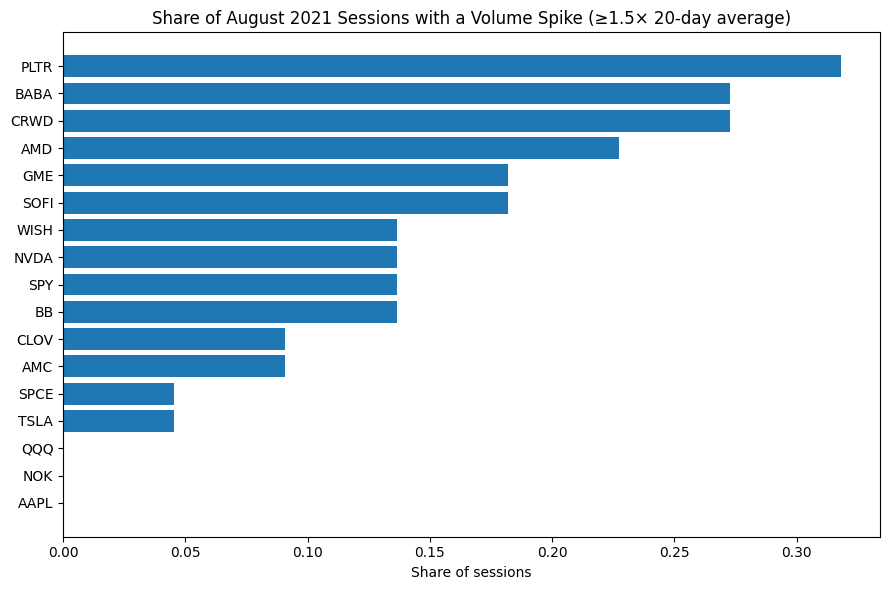

In [ ]:
# Plot the share of sessions with a volume spike ≥1.5× the 20-day average

rates = target.groupby("ticker")["spike_1.5"].mean().sort_values()

plt.figure(figsize=(9, 6))
plt.barh(rates.index, rates.values)
plt.title("Share of August 2021 Sessions with a Volume Spike (≥1.5× 20-day average)")
plt.xlabel("Share of sessions")
plt.tight_layout()
plt.show()

### Volume-Spike Findings

- We define a spike as volume at least **1.5× the average of the previous 20 trading days** for that ticker. Our Phase 1 proposal planned to lower the threshold if 2× produced too few positive cases. At 2×, only **28 of 374 ticker-sessions (7.5%)** are spikes, compared with 36 at 1.75× and **50 (13.4%) at 1.5×**, so we use 1.5×.

- PLTR, BABA, CRWD, NVDA, and SOFI reported earnings in August, and several are among the tickers with the highest spike rates. Earnings may explain some of this activity, so Phase 3 will include an earnings control to help separate it from activity associated with Reddit.

- AAPL, QQQ, and NOK had no spikes at this threshold during August. They add negative examples but no positive cases.

- We excluded HOOD because its July 29, 2021 listing left insufficient history for a full 20-day baseline at the start of August. WISH’s historical volume was retrieved using LOGC, the symbol ContextLogic adopted in 2024.

- The sample contains **374 ticker-sessions across 22 trading days**. With only 50 positive cases and a short time window, Phase 3 will use a small feature set and combine emotion measures rather than include many separate variables.

## Matching Comments to Trading Sessions

Each comment is assigned to the next market open (9:30 a.m. New York time) after it was posted, so features for a session only use text written before that session began.

In [ ]:
# Market opens (9:30 New York time) for every trading day downloaded from yfinance
opens = pd.DataFrame({"session_date": prices.index})
opens["open_et"] = (
    opens["session_date"] + pd.Timedelta(hours=9, minutes=30)
).dt.tz_localize("America/New_York").dt.as_unit("us")

def assign_sessions(df, time_col="created_datetime"):
    """Label each comment with the first market open at or after it was posted."""
    out = df.copy()
    out["created_et"] = out[time_col].dt.tz_convert("America/New_York").dt.as_unit("us")
    out = out.sort_values("created_et")
    return pd.merge_asof(out, opens, left_on="created_et", right_on="open_et", direction="forward")

comments_s = assign_sessions(comments_clean)
comments_s = comments_s.loc[comments_s["session_date"].between("2021-08-02", "2021-08-31")].copy()
print(f"Comments assigned to August sessions: {len(comments_s):,}")
print("Sessions:", comments_s["session_date"].nunique())   

Comments assigned to August sessions: 797,239
Sessions: 22


In [19]:
# Testing the rule

ny = lambda s: pd.Timestamp(s, tz="America/New_York")
cols = ["created_et", "session_date"]

print("Saturday -> Monday");          display(comments_s.loc[comments_s["created_et"].dt.dayofweek == 5, cols].head(2))
print("Fri Aug 13, 2 pm -> Mon Aug 16"); display(comments_s.loc[comments_s["created_et"].between(ny("2021-08-13 14:00"), ny("2021-08-13 14:05")), cols].head(2))
print("Tue Aug 10, 8 am -> same day"); display(comments_s.loc[comments_s["created_et"].between(ny("2021-08-10 08:00"), ny("2021-08-10 08:05")), cols].head(2))

Saturday -> Monday


,created_et,session_date
0,2021-07-31 20:00:03-04:00,2021-08-02
1,2021-07-31 20:00:05-04:00,2021-08-02


Fri Aug 13, 2 pm -> Mon Aug 16


,created_et,session_date
348745,2021-08-13 14:00:02-04:00,2021-08-16
348746,2021-08-13 14:00:03-04:00,2021-08-16


Tue Aug 10, 8 am -> same day


,created_et,session_date
242291,2021-08-10 08:00:02-04:00,2021-08-10
242292,2021-08-10 08:00:05-04:00,2021-08-10


In [ ]:
# Find tickers in each comment (reuses Alex's find_tickers)
comments_s["tickers"] = comments_s["body"].apply(find_tickers)

session_totals = comments_s.groupby("session_date").size().rename("total_comments").reset_index()

mentions = (
    comments_s[["session_date", "tickers"]]
    .explode("tickers").dropna()
    .rename(columns={"tickers": "ticker"})
    .groupby(["session_date", "ticker"]).size()
    .rename("mentions").reset_index()
)

ticker_sessions = (
    target.reset_index()
    .merge(mentions, on=["session_date", "ticker"], how="left")
    .merge(session_totals, on="session_date", how="left")
)
ticker_sessions["mentions"] = ticker_sessions["mentions"].fillna(0).astype(int)  
ticker_sessions["mentions_per_1k"] = ticker_sessions["mentions"] / ticker_sessions["total_comments"] * 1000

print(ticker_sessions.shape)   
ticker_sessions.groupby("spike_1.5")[["mentions", "mentions_per_1k"]].median()

(374, 11)


,mentions,mentions_per_1k
spike_1.5,,
False,79.0,2.243829
True,229.0,6.189971


In [21]:
# Compare each ticker-session to that ticker's own typical mention level
ticker_sessions["mentions_vs_own_median"] = (
    ticker_sessions["mentions"] / ticker_sessions.groupby("ticker")["mentions"].transform("median")
)
ticker_sessions.groupby("spike_1.5")["mentions_vs_own_median"].median()

spike_1.5
False    0.966901
True     2.323848
Name: mentions_vs_own_median, dtype: float64

### Session Alignment and Mention Activity

We assigned each comment to the next **9:30 a.m. New York market open**, and all three checks passed: Saturday mapped to Monday, Friday afternoon mapped to Monday, August 16, and Tuesday at 8 a.m. mapped to the same day’s open. The August 2 window is shorter because the dataset begins on Saturday evening, so that session does not have a full comment window.

Spike sessions had a median of **229 mentions**, compared with **79** for normal sessions, or **6.2 versus 2.2 mentions per 1,000 comments**. Relative to each ticker’s own monthly median, mention activity was **2.32× before spike sessions versus 0.97× before normal sessions**, which is consistent with our Phase 1 hypothesis that attention matters.

These results are descriptive, not evidence of predictive performance: the monthly median includes later dates, so Phase 3 must calculate mention velocity using only earlier information. Earnings news could also drive both pre-open discussion and trading volume, so Phase 3 will include an earnings control before treating attention as an independent predictor.

# 2.	Text Mining Basics (about 50% of the notebook)
- Keyword/frequency analysis: top keywords, word clouds, or bar charts
- Sentiment analysis: baseline sentiment scores (lexicon-based or a simple model) across your text
- Topic modeling or NER, only if relevant to your problem
- Use visuals (bar charts, word clouds, tables) and briefly interpret what you see. Make sure this ties back to your problem or informs your next-stage model building, rather than just checking off a list.


### Keyword Frequency

We count how many ticker-mentioning comments contain each word, per 1,000 comments. Each comment counts once per word, so a single long comment cannot dominate. Common English words and the ticker symbols themselves are excluded.

In [23]:
import numpy as np
from sklearn.feature_extraction.text import CountVectorizer, ENGLISH_STOP_WORDS

# One row per (comment, ticker it mentions), labelled with that ticker-session's spike flag
pairs = (
    comments_s.loc[comments_s["tickers"].str.len() > 0, ["id", "session_date", "tickers", "body"]]
    .explode("tickers").rename(columns={"tickers": "ticker"})
    .merge(ticker_sessions[["session_date", "ticker", "spike_1.5"]],
           on=["session_date", "ticker"], how="inner")
)
print(f"Comment-ticker pairs: {len(pairs):,}")
print(f"Before spike sessions: {pairs['spike_1.5'].sum():,}")

# Exclude common English words and the ticker symbols themselves
stop = list(ENGLISH_STOP_WORDS) + [t.lower() for t in tickers]
vec = CountVectorizer(stop_words=stop, binary=True, min_df=20,
                      token_pattern=r"(?u)\b[a-zA-Z][a-zA-Z']+\b")
X = vec.fit_transform(pairs["body"])

kw = pd.DataFrame({
    "word": vec.get_feature_names_out(),
    "overall_per_1k": np.asarray(X.mean(axis=0)).ravel() * 1000,
})

Comment-ticker pairs: 62,684
Before spike sessions: 18,282


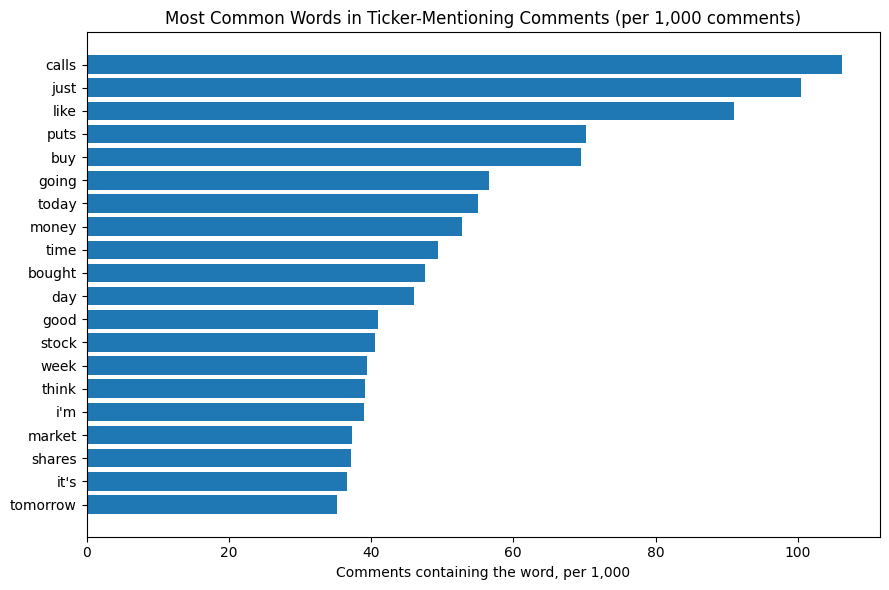

In [24]:
top = kw.nlargest(20, "overall_per_1k").sort_values("overall_per_1k")
plt.figure(figsize=(9, 6))
plt.barh(top["word"], top["overall_per_1k"])
plt.title("Most Common Words in Ticker-Mentioning Comments (per 1,000 comments)")
plt.xlabel("Comments containing the word, per 1,000")
plt.tight_layout()
plt.show()

### Keyword Findings

Options language is prominent: “calls” appears in about **106 of every 1,000 ticker-mentioning comments**, compared with **70 for “puts”**, a ratio of roughly 1.5 to 1, suggesting a focus on short-term options bets and a possible bullish lean.

Words such as “today,” “tomorrow,” “day,” and “week” suggest a short-term focus, which fits our next-session prediction task. Words such as “buy,” “bought,” “shares,” “money,” and “market” also show the trading focus of these discussions.

Some filler, including “just,” “like,” “i’m,” and “it’s,” remains after stopword filtering, but it does not change the main pattern.

About **29% of comment–ticker pairs (18,282 of 62,684)** fall before spike sessions, even though spikes account for only **13.4% of ticker-sessions**. This is consistent with our earlier finding that discussion activity is higher before volume spikes, although it does not establish predictive performance.

### Words Before Spike vs. Normal Sessions

We compare each word's rate per 1,000 comments before spike sessions with its rate before normal sessions. Rare words are excluded, and the comparison uses a log ratio: positive values mean a word is relatively more common before spikes.

In [25]:
is_spike = pairs["spike_1.5"].astype(bool).to_numpy()
kw["spike_per_1k"] = np.asarray(X[is_spike].mean(axis=0)).ravel() * 1000
kw["normal_per_1k"] = np.asarray(X[~is_spike].mean(axis=0)).ravel() * 1000

# Keep words used in at least 2 of every 1,000 comments, then compare the two rates
common = kw[kw["overall_per_1k"] >= 2].copy()
common["log_ratio"] = np.log2((common["spike_per_1k"] + 0.5) / (common["normal_per_1k"] + 0.5))

contrast = pd.concat([
    common.nlargest(15, "log_ratio"),
    common.nsmallest(15, "log_ratio"),
]).sort_values("log_ratio")

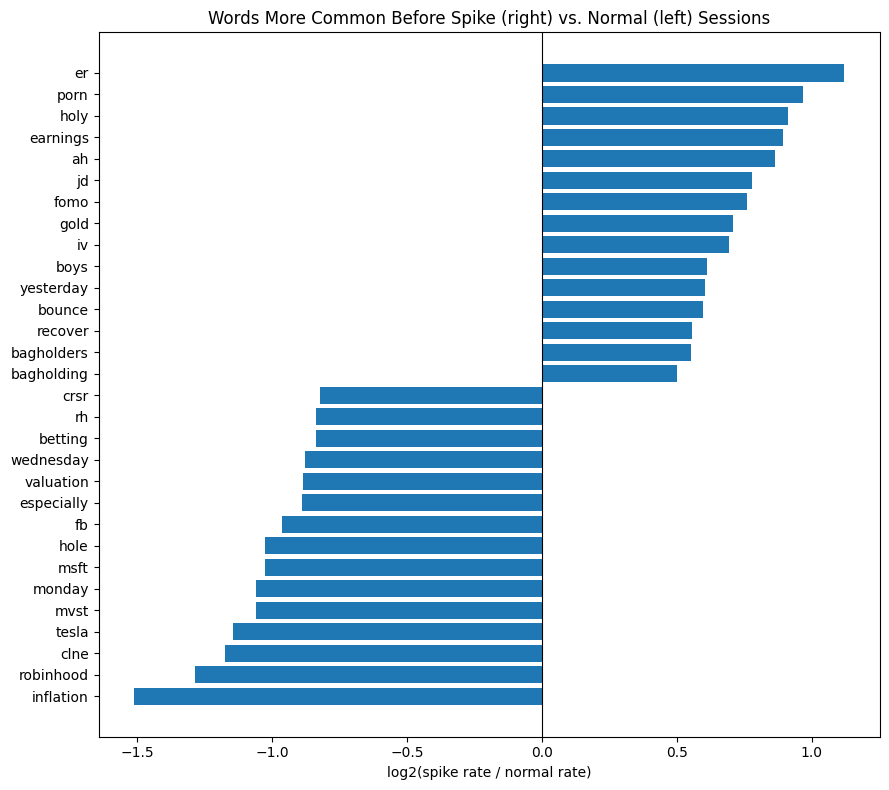

,word,spike_per_1k,normal_per_1k,log_ratio
1424,inflation,0.71,2.95,-1.51
2364,robinhood,2.02,5.65,-1.29
500,clne,2.79,6.91,-1.17
2800,tesla,2.08,5.20,-1.15
1833,mvst,4.05,8.99,-1.06
1794,monday,4.32,9.55,-1.06
1825,msft,3.34,7.32,-1.03
1337,hole,1.09,2.75,-1.03
1003,fb,1.04,2.50,-0.96
905,especially,2.41,4.89,-0.89


In [26]:
plt.figure(figsize=(9, 8))
plt.barh(contrast["word"], contrast["log_ratio"])
plt.axvline(0, color="black", linewidth=0.8)
plt.title("Words More Common Before Spike (right) vs. Normal (left) Sessions")
plt.xlabel("log2(spike rate / normal rate)")
plt.tight_layout()
plt.show()

contrast[["word", "spike_per_1k", "normal_per_1k", "log_ratio"]].round(2)

### Words Before Spike and Normal Sessions

Earnings-related words are more common before spike sessions. “Earnings” appears in about **41 per 1,000 comments versus 22** before normal sessions, alongside “er” (earnings report) and “ah” (after hours). This adds text evidence for including an earnings control in Phase 3.

Words such as “holy,” “fomo,” and “porn” (WSB slang, as in “gain porn” or “loss porn”) suggest stronger reactions, while “bagholders,” “bagholding,” “bounce,” and “recover” mix losses with hopes of a rebound. This suggests that emotional intensity may matter alongside sentiment direction, rather than every spike having a clearly positive or negative tone.

Before normal sessions, words such as “inflation” and “valuation,” along with other stock names, may reflect broader market discussion. “Tesla” and “robinhood” also remind us that our regex recognizes ticker symbols but does not capture company names by themselves.

These patterns are descriptive: a few events could drive individual words, including possible BABA-related discussion behind “jd,” and a comment mentioning multiple tickers can contribute to both groups. For Phase 3, we will test a few dictionary-based features, such as the share of comments containing earnings terms (“earnings,” “er,” “ah”), volatility language (“iv”), or reaction words (“fomo,” “holy”), rather than start with thousands of TF-IDF features.

### Baseline Sentiment: VADER

We score each ticker-mentioning comment with VADER, a lexicon-based sentiment tool, and compare it with the sentiment score supplied in the dataset.

In [27]:
from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer

vader = SentimentIntensityAnalyzer()

# Score each ticker-mentioning comment once
ticker_texts = comments_s.loc[comments_s["tickers"].str.len() > 0, ["id", "body", "sentiment"]].copy()
ticker_texts["vader"] = ticker_texts["body"].apply(lambda t: vader.polarity_scores(t)["compound"])
print(f"Comments scored: {len(ticker_texts):,}")

Comments scored: 63,344


In [28]:
# How does our VADER score compare with the supplied score?
both = ticker_texts.dropna(subset=["sentiment"])
print("Correlation with supplied sentiment:", round(both["vader"].corr(both["sentiment"]), 3))
print("Exact matches (to 4 decimals):", f"{(both['vader'].round(4) == both['sentiment'].round(4)).mean():.1%}")

Correlation with supplied sentiment: 1.0
Exact matches (to 4 decimals): 100.0%


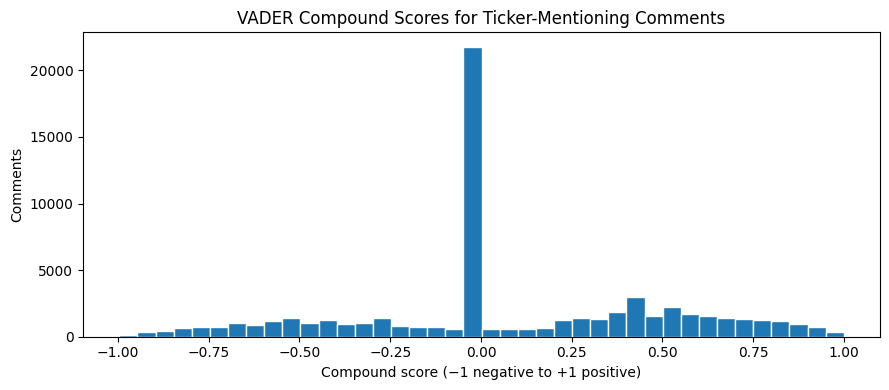

Share exactly neutral (0): 33.7%


In [29]:
# Distribution of VADER scores
plt.figure(figsize=(9, 4))
plt.hist(ticker_texts["vader"], bins=40, edgecolor="white")
plt.title("VADER Compound Scores for Ticker-Mentioning Comments")
plt.xlabel("Compound score (−1 negative to +1 positive)")
plt.ylabel("Comments")
plt.tight_layout()
plt.show()

print("Share exactly neutral (0):", f"{(ticker_texts['vader'] == 0).mean():.1%}")

### VADER Sentiment Findings

Our check identified the supplied sentiment column as VADER, with a **correlation of 1.0 and 100% exact matches**, so we use our own VADER scores to also cover comments where the supplied score was missing. **33.7% of ticker-mentioning comments receive a compound score of exactly 0**, which VADER treats as neutral.

A likely contributor is that WSB’s directional terms, such as “calls” and “puts,” are missing from VADER’s lexicon, so comments like “Bought 30c of HOOD” can register as neutral despite expressing a trading position. Outside zero, scores lean slightly positive, broadly consistent with calls outnumbering puts, although neither finding alone confirms a bullish stance.

### The vocabulary gap and sentiment before spikes

In [30]:
# Common WSB trading terms: does VADER's lexicon contain them, and how often do they appear?
wsb_terms = ["calls", "puts", "bullish", "bearish", "moon", "tendies", "squeeze", "yolo",
             "fomo", "bagholders", "bagholding", "dip", "pump", "dump", "iv", "earnings",
             "short", "rip", "apes", "printing"]

gap = pd.DataFrame({
    "term": wsb_terms,
    "in_vader_lexicon": [t in vader.lexicon for t in wsb_terms],
})
gap = gap.merge(kw[["word", "overall_per_1k"]], left_on="term", right_on="word", how="left").drop(columns="word")
gap["overall_per_1k"] = gap["overall_per_1k"].fillna(0).round(1)

print(f"Missing from VADER: {(~gap['in_vader_lexicon']).sum()} of {len(gap)} terms")
gap.sort_values("overall_per_1k", ascending=False)

Missing from VADER: 18 of 20 terms


,term,in_vader_lexicon,overall_per_1k
0,calls,False,106.2
1,puts,False,70.2
15,earnings,False,27.5
16,short,False,23.3
11,dip,False,19.2
4,moon,False,17.7
6,squeeze,False,14.9
12,pump,False,12.2
13,dump,True,11.8
18,apes,False,10.4


In [31]:
# Attach each comment's VADER score to its ticker-session
scored = pairs.merge(ticker_texts[["id", "vader"]], on="id", how="left")

session_sent = (
    scored.groupby(["session_date", "ticker"])
    .agg(mean_vader=("vader", "mean"),
         mean_intensity=("vader", lambda s: s.abs().mean()),
         share_neutral=("vader", lambda s: (s == 0).mean()),
         n_comments=("vader", "size"))
    .reset_index()
)

ticker_sessions = ticker_sessions.drop(columns=[c for c in session_sent.columns
                                                if c in ticker_sessions.columns and c not in ("session_date", "ticker")])
ticker_sessions = ticker_sessions.merge(session_sent, on=["session_date", "ticker"], how="left")

print("Ticker-sessions with no comments (no sentiment):", ticker_sessions["mean_vader"].isna().sum())
ticker_sessions.groupby("spike_1.5")[["mean_vader", "mean_intensity", "share_neutral"]].median().round(3)

Ticker-sessions with no comments (no sentiment): 0


,mean_vader,mean_intensity,share_neutral
spike_1.5,,,
False,0.089,0.321,0.344
True,0.096,0.321,0.350


### VADER Vocabulary and Session Sentiment

VADER’s lexicon is missing **18 of the 20 WSB trading terms** we checked, including the four most frequent in our list: “calls” (**106 per 1,000 comments**), “puts” (**70**), “earnings” (**28**), and “short” (**23**). Only “dump” and “yolo” are present.

VADER sentiment is nearly the same before normal and spike sessions. Mean direction is **0.089 versus 0.096**, intensity is **0.321 for both**, and the neutral share is **34.4% versus 35.0%**. In contrast, mention activity before spike sessions reached about **2.3× each ticker’s own monthly median**.

This leaves an open question: does mood add little predictive information, or does VADER miss the language that matters on WSB? Phase 3 will compare VADER features with Claude’s bullish/bearish polarity and emotion labels to test whether either adds predictive value beyond attention.

In this sample, **every ticker-session had at least one comment**, so no session-level sentiment values were missing. A session with no comments would mean missing sentiment, not neutral sentiment. Averages for small tickers can still be noisy, so we will keep comment counts alongside the sentiment features.

### Topic Modeling and Named Entity Recognition

We did not apply topic modeling or NER. Our unit of analysis is the ticker-session, and tickers are already identified directly through symbol matching. General-purpose NER models are not trained on WSB slang or ticker symbols, and topic modeling would describe broad themes without producing the small set of ticker-level features our Phase 3 model can support with 50 positive cases.

# 3.	Plan for Phase 3 (about 25% of the notebook)
- Which analysis path, A or B, are you pursuing, and why does the data or the business problem support it?
- If you plan to use Claude (or any other LLM of your choice: note the class only provides Claude API keys), what specifically will it do, and have you tried a few sample prompts?
- If you’re not using an LLM at all, explain why. That’s completely fine, and sometimes the better choice.
- Are there any concerns with your approach (privacy, scale, token usage, validity of LLM results, etc.)?


### Sample Prompts Tried

We tested a draft labelling prompt on real ticker-mentioning comments, chosen to include cases VADER scores as exactly neutral despite trading language.

In [ ]:
import json
import anthropic

from dotenv import load_dotenv
load_dotenv("../.env")           
client = anthropic.Anthropic()

SYSTEM = """You label r/wallstreetbets comments about a specific stock ticker.
Return ONLY a JSON object with these keys:
- "relevant": true if the comment is actually about the ticker as a stock, else false
- "stance": "bullish", "bearish", "neutral", or "unclear" toward THAT ticker
- "emotion": "excitement_fomo", "fear_panic", "anger", "uncertainty", or "none"
- "intensity": "high" or "low"
- "catalyst": "earnings", "squeeze", "other_news", or "none"
Notes: buying calls is bullish, buying puts is bearish. "Bagholding" means holding a losing position."""

def label(ticker, comment):
    msg = client.messages.create(
        model="claude-haiku-5-5",
        max_tokens=1024,         
        system=SYSTEM,
        messages=[{"role": "user", "content": f"Ticker: {ticker}\nComment: {comment}"}],
    )
    # The reply can contain a thinking block first; keep only the text answer
    text = next(block.text for block in msg.content if block.type == "text")
    text = text.strip().removeprefix("```json").removeprefix("```").removesuffix("```").strip()
    return json.loads(text)

# Pick test cases: VADER-neutral comments that use calls/puts, plus a random few
samples = scored.merge(ticker_texts[["id", "body"]], on="id", suffixes=("", "_t"))
neutral_options = samples[(samples["vader"] == 0) & samples["body"].str.contains(r"\b(?:calls|puts)\b", case=False)]
test = pd.concat([neutral_options.sample(3, random_state=1), samples.sample(3, random_state=7)])

results = []
for _, row in test.iterrows():
    out = label(row["ticker"], row["body"])
    results.append({"ticker": row["ticker"], "comment": row["body"][:150], "vader": row["vader"], **out})

pd.DataFrame(results)

,ticker,comment,vader,relevant,stance,emotion,intensity,catalyst
0,AMD,AMD puts clapped me,0.0000,True,bearish,anger,low,none
1,NVDA,Bought some NVDA Nov calls this morning.\n\nUh should went in harder.,0.0000,True,bullish,excitement_fomo,low,none
2,SPY,"So.... When we buying SPY calls, boys?",0.0000,True,bullish,excitement_fomo,low,none
3,GME,"Mods. Ban GME cucks from this sub. They have their own AIDS for your screen, unclever sub.",-0.5574,False,unclear,anger,high,none
4,NVDA,Gunna have to take the other side of that trade\n\nNVDA = company that is selling more and more things\n\nAMC = Company that is burning cash on rent to st,0.2651,True,bullish,none,low,none
5,SPY,"Everything is screaming another bull run out of the pit SPY dug itself here, but something feels off. Can’t describe what it is. Idk going to be a gay",-0.3400,True,bearish,uncertainty,low,none


### Claude Labelling Pilot

Claude assigned directional labels to all three options comments that VADER scored as neutral. The relevance check also flagged the off-topic GME comment despite its negative VADER score, and the comment mentioning both NVDA and AMC received a label for the requested ticker, NVDA.

The “AMD puts clapped me” example shows why the prompt needs a clearer stance definition: losing money on puts does not necessarily reveal the author’s current outlook. We will define stance as **the author’s current view of where the target stock is going**, using “unclear” when that view cannot be inferred.

Intensity may be too conservative: five of the six comments were labelled “low,” including “should went in harder.” We will add examples of high and low intensity to make that distinction clearer.

These six examples show useful behaviour and prompt weaknesses, not evidence of overall accuracy. In Phase 3, we will hand-check **100 labels** to assess relevance, stance, emotion, and intensity before using them as model features.

## Phase 3 Plan

### Path and Target

We will follow **Path A: classification**, predicting whether a ticker-session’s volume reaches at least **1.5× its previous 20-session average**. We calculate the target from yfinance volume data, so the target labels do not require manual labelling. We have **50 positive cases across 374 ticker-sessions**, so we will keep the model small and treat the results as exploratory.

### Features

We will start with a small set of features rather than include everything at once:

- **Volume momentum:** the previous session’s volume divided by its preceding 20-session average.
- **Mention velocity:** mentions relative to that ticker’s earlier sessions only, avoiding the full-month median.
- **Sentiment:** VADER or Claude’s bullish/bearish stance.
- **Emotion intensity:** one combined measure, such as the share of high-intensity comments.
- **Earnings:** an indicator based on information available before the prediction cutoff.
- **Optional dictionary features:** shares of comments containing earnings terms, “iv,” or “fomo,” if they improve validation results.

### Models and Verification

Our main model will be **logistic regression**, which is easier to interpret, with a small gradient boosting model as a comparison. We will hand-check 100 Claude labels before using them as features.

We will compare:
- Volume-only features against volume plus Reddit features.
- VADER, Claude polarity, and Claude emotion as alternative features.
- Models with and without the earnings indicator.

The higher mention activity before spikes gives us a reason to test Reddit features, but it does not establish predictive performance. If Reddit adds no improvement over the volume-only baseline, we will report that result.

### Evaluation

Because we only have 22 sessions, we will use **expanding-window evaluation**: train on sessions 1 to k, test on session k+1, then expand the training window and repeat, so each later session is tested once using only earlier data.

We will use **time-ordered splits**, training on earlier sessions and testing on later ones, never a random split. Feature choices will be made using earlier validation periods rather than the final test period.

For the watchlist check, we will rank tickers by predicted spike probability each morning and report **how many of the top three actually spiked**. All features must use information available before that session’s 9:30 a.m. New York open.

In [39]:
# Token Usage Calculation

msg = client.messages.create(
    model="claude-haiku-5-5", max_tokens=1024, system=SYSTEM,
    messages=[{"role": "user", "content": "Ticker: NVDA\nComment: Bought some NVDA Nov calls this morning."}],
)
print("input tokens:", msg.usage.input_tokens, "| output tokens:", msg.usage.output_tokens)

input tokens: 260 | output tokens: 45


## Concerns and Limitations

- **Size and generalisation:** We have only 22 trading sessions and 50 positive cases, so the results are exploratory. One month of WSB activity during the 2021 meme-stock period may not represent other periods or trading communities.

- **Earnings confound:** News can drive both Reddit discussion and trading volume. We will include an earnings control and compare results with and without it rather than assume Reddit caused the spikes.

- **LLM validity:** We have no supplied human-labelled ground truth for trading stance or emotion. Claude’s labels may vary between runs, and the API rejected a temperature setting for this model in our tests. We will hand-check 100 labels, revise unclear prompt definitions, and save the final labels with the prompt and model information instead of repeatedly regenerating them.

- **Cost and scale:** Our test request used 260 input tokens and 45 output tokens. At Haiku 5.5 rates of $0.10 per million input tokens and $0.50 per million output tokens, 63,344 similar requests would cost approximately **$3.07**, or **$1.54 through the Batch API**. This is a projection from one short example, not a measured full-dataset cost. Longer comments, retries, and separate ticker-specific requests could increase it. Thinking tokens count as output and are already included in the API’s reported output-token total.

- **Privacy:** The comments are public, and the dataset contains no author field. However, comment text could still contain identifying details. Text is sent to Claude for labelling, while the prediction models use aggregated ticker-session features rather than individual profiles.

- **Data sources:** The Kaggle posts were too limited and GME-dominated for our planned comparison. Arctic Shift time-range pulls worked, but text and thread queries repeatedly timed out. We chose SocialGrep because it provides a larger, pre-collected comment dataset with timestamps, although its August-only coverage limits the study.

### How We Addressed the Professor’s Feedback

- **Test data collection:** We tested live collection through Arctic Shift before committing. Time-range pulls worked, returning about 2,400 comments per busy hour, but text and thread queries repeatedly timed out, so we used a pre-collected dataset.

- **Comment-level scoring and aggregation:** We score individual comments for the target ticker, then aggregate the results into ticker-session features.

- **Zero-mention sessions and multiple tickers:** Every ticker-session in our sample has at least one comment. A session without comments would have missing sentiment, not neutral sentiment. A comment naming several tickers counts toward each, and Claude labels stance separately for each ticker.

- **Pre-open cutoff:** Features use only information available before the session’s 9:30 a.m. New York open.

- **Direct Claude use:** We use Claude’s labels directly as features rather than training a separate sentiment classifier on 500 Claude-labelled comments, as originally proposed.

- **Emotion features:** We will compare VADER, Claude polarity, and Claude emotion or intensity features to see which adds predictive value.

- **TF-IDF and feature size:** We do not use TF-IDF n-grams as model features; keyword analysis stays descriptive (word rates per 1,000 comments). Prediction will use a small set of aggregated features, including dictionary measures if they improve validation results

- **Watchlist evaluation:** We will use expanding-window evaluation and report how many of each morning’s top three tickers actually spike.

- **Repository setup:** The repository includes an MIT LICENSE. The API key is loaded from `.env`, which is excluded from version control, as are processed data files.